<a href="https://colab.research.google.com/github/JuanTorresCol/Object-Detection-and-Segmentation/blob/main/JuanTorres_Assignment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This code has been ran on September 14 2026 using release August 6 2026 of Google Colab Pro.

In [ ]:
#!pip install -U "protobuf>=6.31.1"
!pip install -U protobuf tensorflow-metadata tensorflow-datasets

  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.33.6
    Uninstalling protobuf-6.33.6:
      Successfully uninstalled protobuf-6.33.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [ ]:
!pip install -U importlib-resources

In [ ]:
import importlib_resources
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "oxford_iiit_pet:4.0.0",
    with_info=True
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.PZ5R9M_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.PZ5R9M_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.


In [ ]:
# Re-import the libraries after reinstalling them to ensure the new versions are used
import tensorflow as tf
import matplotlib.pylab as plt
import numpy as np
import cv2

In [ ]:
def read_and_preprocess(data):
  input_image = tf.image.resize(data['image'], (128, 128), method='bilinear')
  input_mask = tf.image.resize(data['segmentation_mask'], (128, 128), method='nearest')
  input_image = tf.image.convert_image_dtype(tf.cast(input_image, tf.uint8), tf.float32)
  input_mask = tf.cast(input_mask, tf.int32) - 1  # {1,2,3} -> {0,1,2}
  return input_image, input_mask

In [ ]:
train = dataset['train'].map(read_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test = dataset['test'].map(read_and_preprocess)

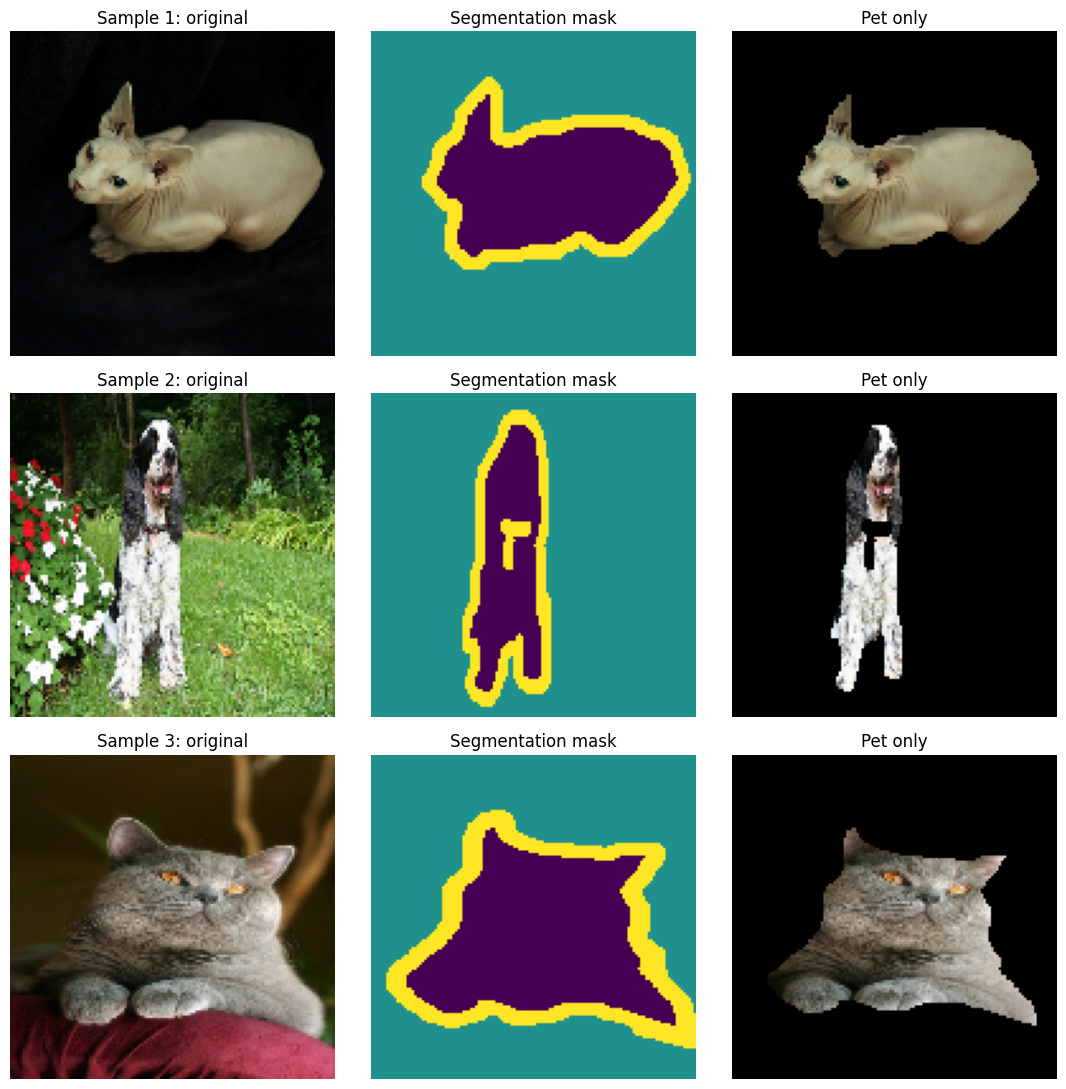

In [ ]:
# b) Create the segmentation mask
# Show some images from dataset and their segmented version
fig, axes = plt.subplots(3, 3, figsize=(11, 11))

for i, (image, mask) in enumerate(train.take(3)):
    image_np = image.numpy()
    mask_np = tf.squeeze(mask).numpy()

    # Keep only the pet pixels to show the segmented object.
    segmented = image_np * (mask_np == 0)[..., np.newaxis]

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title(f'Sample {i + 1}: original')
    axes[i, 1].imshow(mask_np, cmap='viridis', vmin=0, vmax=2)
    axes[i, 1].set_title('Segmentation mask')
    axes[i, 2].imshow(segmented)
    axes[i, 2].set_title('Pet only')

    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()

**Part 2- Annotation**

In [ ]:
import tensorflow as tf
!git clone https://github.com/matterport/Mask_RCNN.git
%cd Mask_RCNN
!python setup.py install
!pip install cython scikit-image
!pip install git+https://github.com/waleedka/coco.git#subdirectory=PythonAPI
import os
import urllib.request

# URL for the pre-trained weights
url = "https://github.com/matterport/Mask_RCNN/releases/download/v2.0/mask_rcnn_coco.h5"
weights_path = "mask_rcnn_coco.h5"

if not os.path.exists(weights_path):
    print("Downloading pre-trained weights...")
    urllib.request.urlretrieve(url, weights_path)
    print("Download complete!")

Cloning into 'Mask_RCNN'...
remote: Enumerating objects: 956, done.
remote: Total 956 (delta 0), reused 0 (delta 0), pack-reused 956 (from 1)
Receiving objects: 100% (956/956), 137.67 MiB | 25.93 MiB/s, done.
Resolving deltas: 100% (558/558), done.
/content/Mask_RCNN
/content/Mask_RCNN/setup.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/setuptools/dist.py:599: SetuptoolsDeprecationWarning: Invalid dash-separated key 'description-file' in 'metadata' (setup.cfg), please use the underscore name 'description_file' instead.
!!

        ********************************************************************************
        Usage of dash-separated 'description-file' will not be supported in future
        versions. Please use the u

In [ ]:
# Get data from here https://github.com/experiencor/raccoon_dataset
!git clone https://github.com/experiencor/raccoon_dataset.git

Cloning into 'raccoon_dataset'...
remote: Enumerating objects: 646, done.
remote: Counting objects: 100% (646/646), done.
remote: Compressing objects: 100% (232/232), done.
remote: Total 646 (delta 413), reused 643 (delta 412), pack-reused 0 (from 0)
Receiving objects: 100% (646/646), 48.00 MiB | 11.65 MiB/s, done.
Resolving deltas: 100% (413/413), done.


Number of images: 200


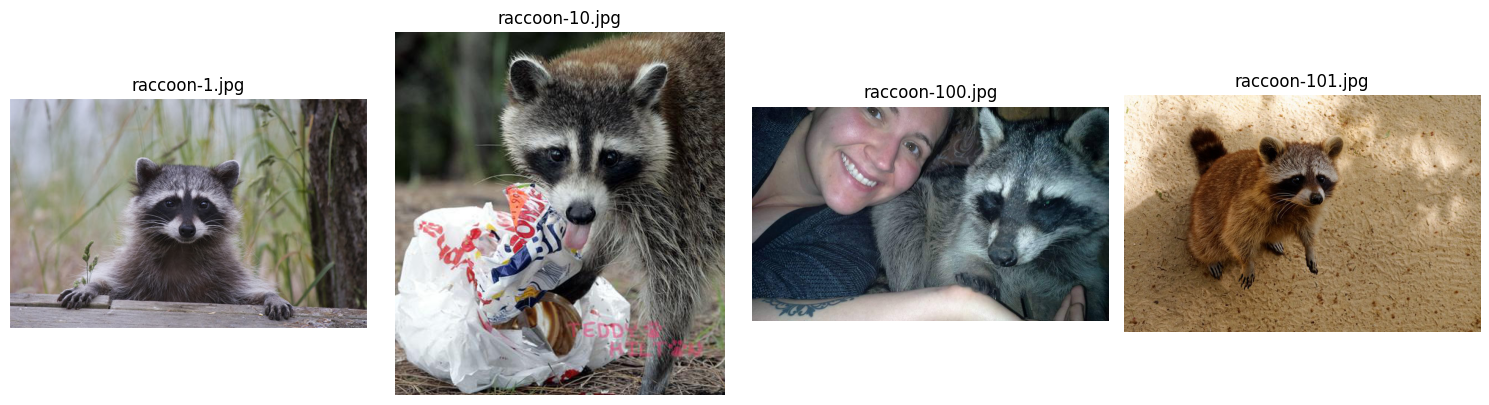

In [ ]:
# Look into data
# Plot some samples here
import os
import matplotlib.pyplot as plt
import cv2

RACCOON_DIR = 'raccoon_dataset'
images_dir = os.path.join(RACCOON_DIR, 'images')
image_files = sorted(
    [f for f in os.listdir(images_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
)

print(f'Number of images: {len(image_files)}')
fig, axes = plt.subplots(1, min(4, len(image_files)), figsize=(15, 4))
if len(image_files) == 1:
    axes = [axes]

for ax, filename in zip(axes, image_files[:4]):
    img = cv2.imread(os.path.join(images_dir, filename))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(filename)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from os import listdir
from xml.etree import ElementTree
from numpy import zeros
from numpy import asarray
from mrcnn.utils import Dataset

# class that defines and loads the raccoon dataset
class RaccoonDataset(Dataset):
	# load the dataset definitions
	def load_dataset(self, dataset_dir, is_train=True):
		# define one class
		self.add_class("raccoon_dataset", 1, "raccoon")
		# define data locations
		images_dir = dataset_dir + '/images/'
		annotations_dir = dataset_dir + '/annotations/raccoon-'
		# find all images
		for filename in listdir(images_dir):
			# extract image id
			image_id = filename[8:-4]
			# skip bad images
			if image_id in ['00090']:
				continue
			# skip all images after 150 if we are building the train set
			if is_train and int(image_id) >= 150:
				continue
			# skip all images before 150 if we are building the test/val set
			if not is_train and int(image_id) < 150:
				continue
			img_path = images_dir + filename
			ann_path = annotations_dir + image_id + '.xml'
			# add to dataset
			self.add_image('dataset', image_id=image_id, path=img_path, annotation=ann_path)

	# extract bounding boxes from an annotation file
	def extract_boxes(self, filename):
		# load and parse the file
		tree = ElementTree.parse(filename)
		# get the root of the document
		root = tree.getroot()
		# extract each bounding box
		boxes = list()
		for box in root.findall('.//bndbox'):
			xmin = int(box.find('xmin').text)
			ymin = int(box.find('ymin').text)
			xmax = int(box.find('xmax').text)
			ymax = int(box.find('ymax').text)
			coors = [xmin, ymin, xmax, ymax]
			boxes.append(coors)
		# extract image dimensions
		width = int(root.find('.//size/width').text)
		height = int(root.find('.//size/height').text)
		return boxes, width, height

	# load the masks for an image
	def load_mask(self, image_id):
		# get details of image
		info = self.image_info[image_id]
		# define box file location
		path = info['annotation']
		# load XML
		#path = '/content/raccoon_dataset/annotations/raccoon-'+image_id   #Added by me
		boxes, w, h = self.extract_boxes(path)
		# create one array for all masks, each on a different channel
		masks = zeros([h, w, len(boxes)], dtype='uint8')
		# create masks
		class_ids = list()
		for i in range(len(boxes)):
			box = boxes[i]
			row_s, row_e = box[1], box[3]
			col_s, col_e = box[0], box[2]
			masks[row_s:row_e, col_s:col_e, i] = 1
			class_ids.append(self.class_names.index('raccoon'))
		return masks, asarray(class_ids, dtype='int32')

	# load an image reference
	def image_reference(self, image_id):
		info = self.image_info[image_id]
		return info['path']

# train set
train_set = RaccoonDataset()
train_set.load_dataset(RACCOON_DIR, is_train=True)
train_set.prepare()
print('Train: %d' % len(train_set.image_ids))

# test/val set
test_set = RaccoonDataset()
test_set.load_dataset(RACCOON_DIR, is_train=False)
test_set.prepare()
print('Test: %d' % len(test_set.image_ids))

Train: 149
Test: 51


Image shape: (360, 640, 3)
Masks shape (height, width, instances): (360, 640, 1)
Class IDs: [1]


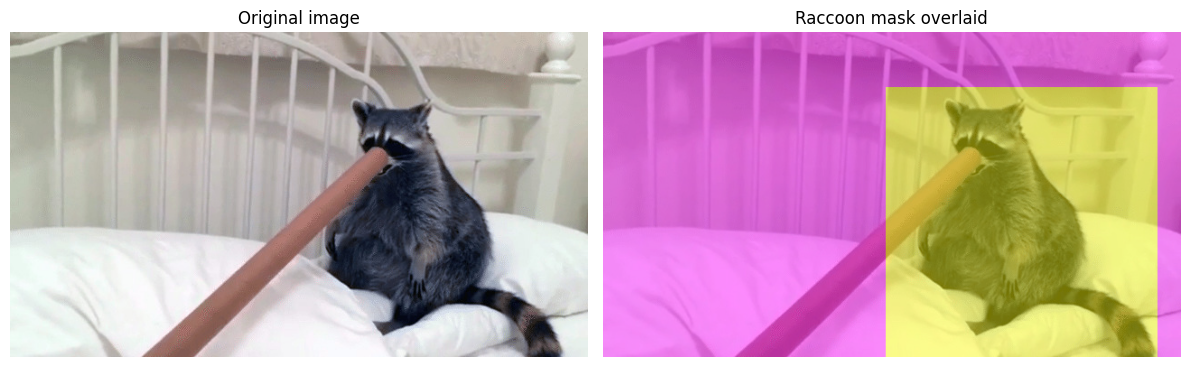

In [ ]:
# load an image
# Use the function above to create the image and its mask
image_id = int(train_set.image_ids[0])
image = train_set.load_image(image_id)
masks, class_ids = train_set.load_mask(image_id)

print('Image shape:', image.shape)
print('Masks shape (height, width, instances):', masks.shape)
print('Class IDs:', class_ids)

# Display the original image and the mask(s).
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title('Original image')
axes[0].axis('off')

if masks.shape[-1] > 0:
    combined_mask = np.any(masks.astype(bool), axis=-1)
else:
    combined_mask = np.zeros(image.shape[:2], dtype=bool)

axes[1].imshow(image)
axes[1].imshow(combined_mask, cmap='spring', alpha=0.45)
axes[1].set_title('Raccoon mask overlaid')
axes[1].axis('off')
plt.tight_layout()
plt.show()

**Part 3- YOLO**



You can see how YOLO has been improved in the last few versions on COCO: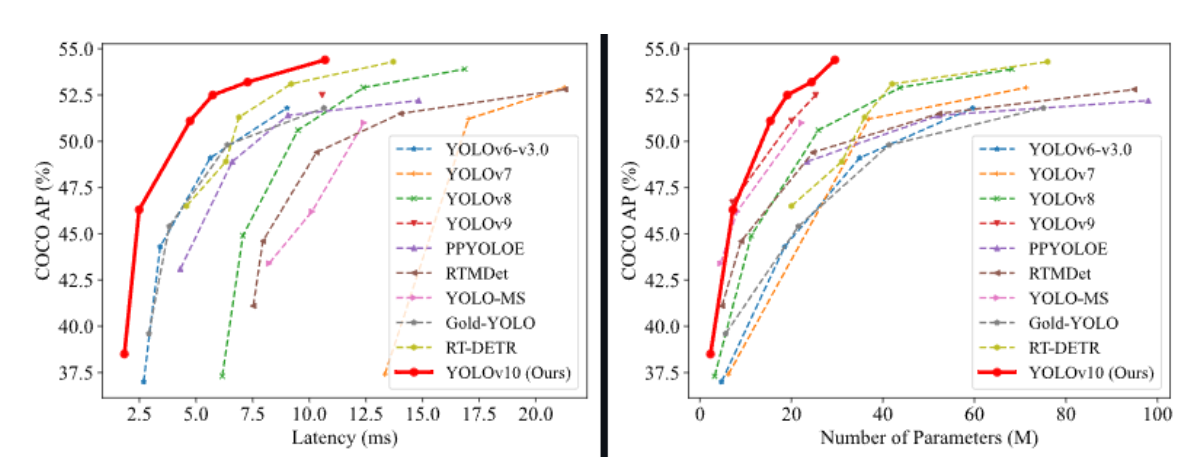

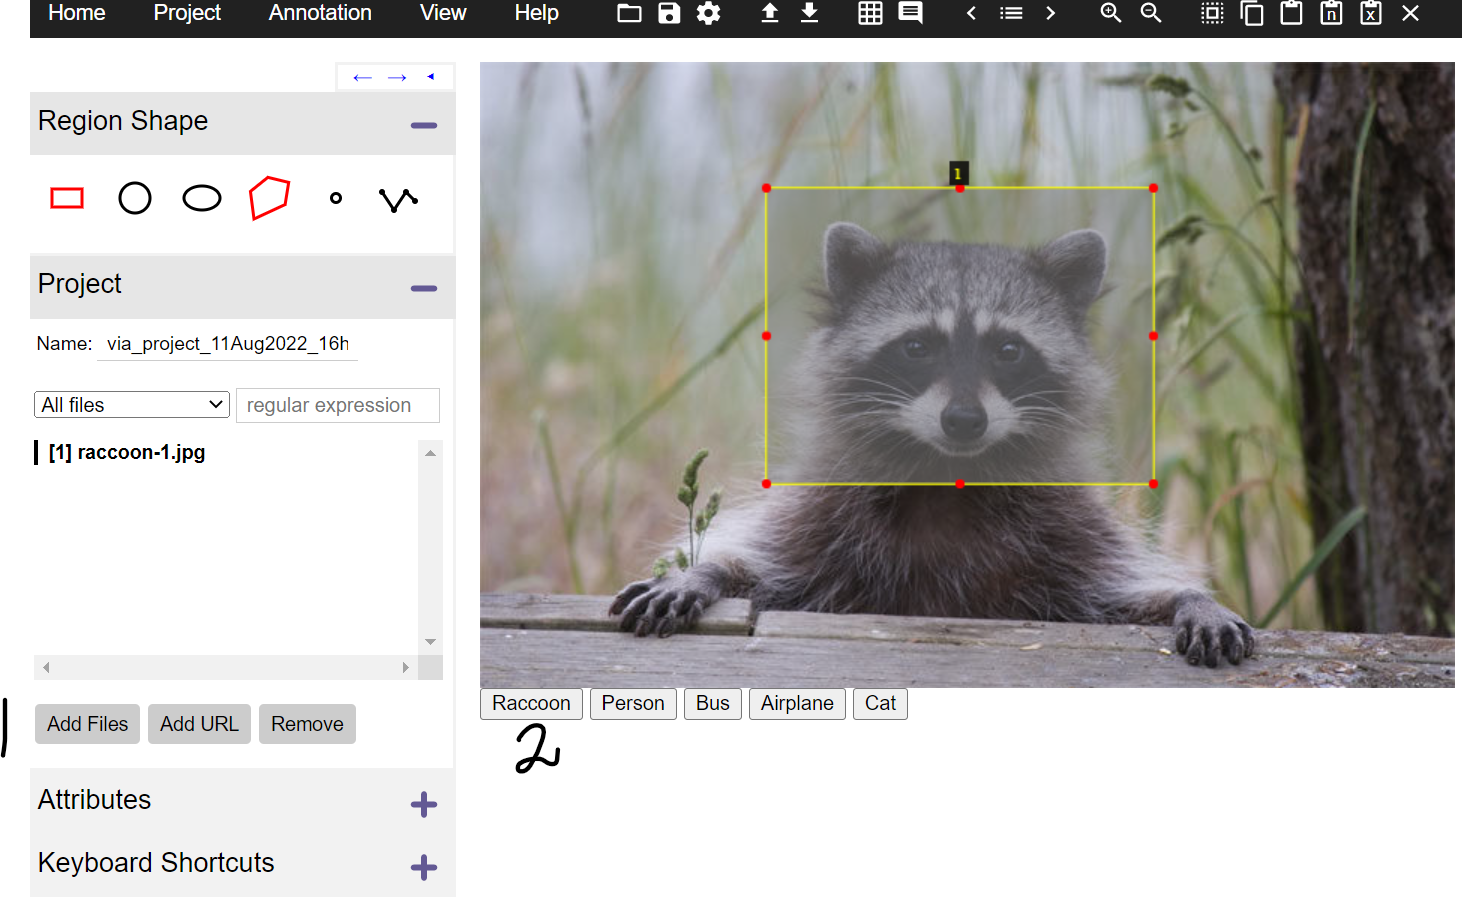

In [ ]:
# a- Create annotation
# You can upload the file using ![title](filename.jpeg)
# import image module


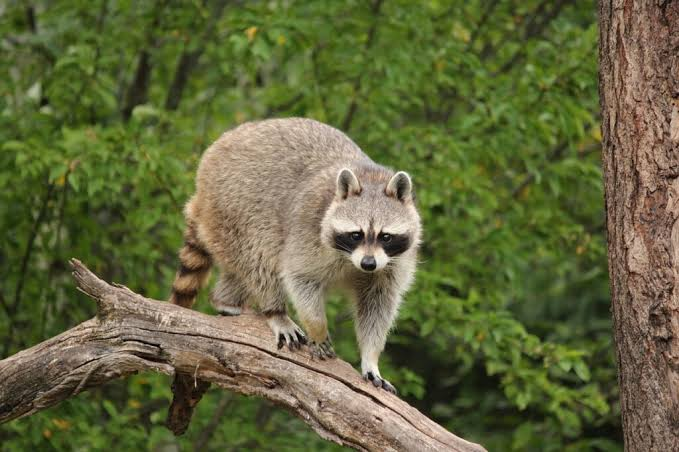

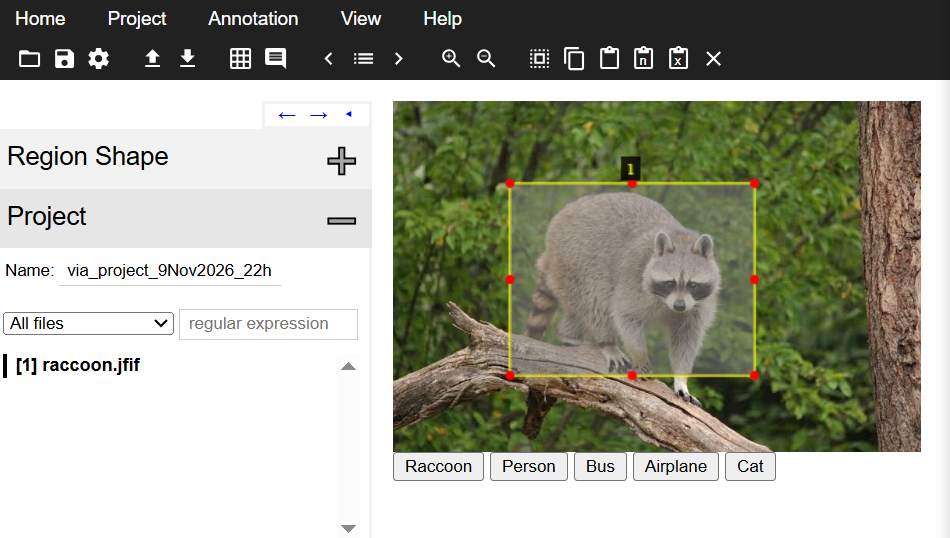

In [ ]:
#Some information about your GPU
!nvidia-smi


Mon Nov  9 22:10:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   69C    P0             31W /   70W |     111MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
#b- Download required tools
import os
HOME = os.getcwd()

In [ ]:
#You can download YOLO 11 model here
!wget https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt -O yolo11n.pt

--2026-11-09 22:13:43--  https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt
Resolving github.com (github.com)... 140.82.116.3
Connecting to github.com (github.com)|140.82.116.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/521807533/34b70ade-b6eb-4179-a60f-d6494307226b?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-09T22%3A56%3A08Z&rscd=attachment%3B+filename%3Dyolo11n.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-11-09T21%3A55%3A25Z&ske=2026-11-09T22%3A56%3A08Z&sks=b&skv=2018-11-09&sig=u3VVj8GAF79zuTw90Ol30xGEELw1Y44LiCuHMUWgeuM%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5NDI2MjcyMywibmJmIjoxNzk0MjYyNDIzLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGlvbi5ibG9iLmNvcmUud

In [ ]:
#c- Test the model out of box
# Update the ultralytics package to the absolute latest version
!pip install -U ultralytics

from ultralytics import YOLO
# Load the locally downloaded model
model = YOLO(os.path.join(HOME, 'yolo11n.pt'))
predictions = model.predict(
    source='https://ultralytics.com/images/bus.jpg',
    save=True,
    conf=0.25
)
prediction_dir = str(predictions[0].save_dir)
predicted_image = os.path.join(prediction_dir, 'bus.jpg')
print('Prediction saved to:', predicted_image)


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/Mask_RCNN/bus.jpg: 640x480 4 persons, 1 bus, 9.5ms
Speed: 2.1ms preprocess, 9.5ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/Mask_RCNN/runs/detect/predict-3
Prediction saved to: /content/Mask_RCNN/runs/detect/predict-3/bus.jpg


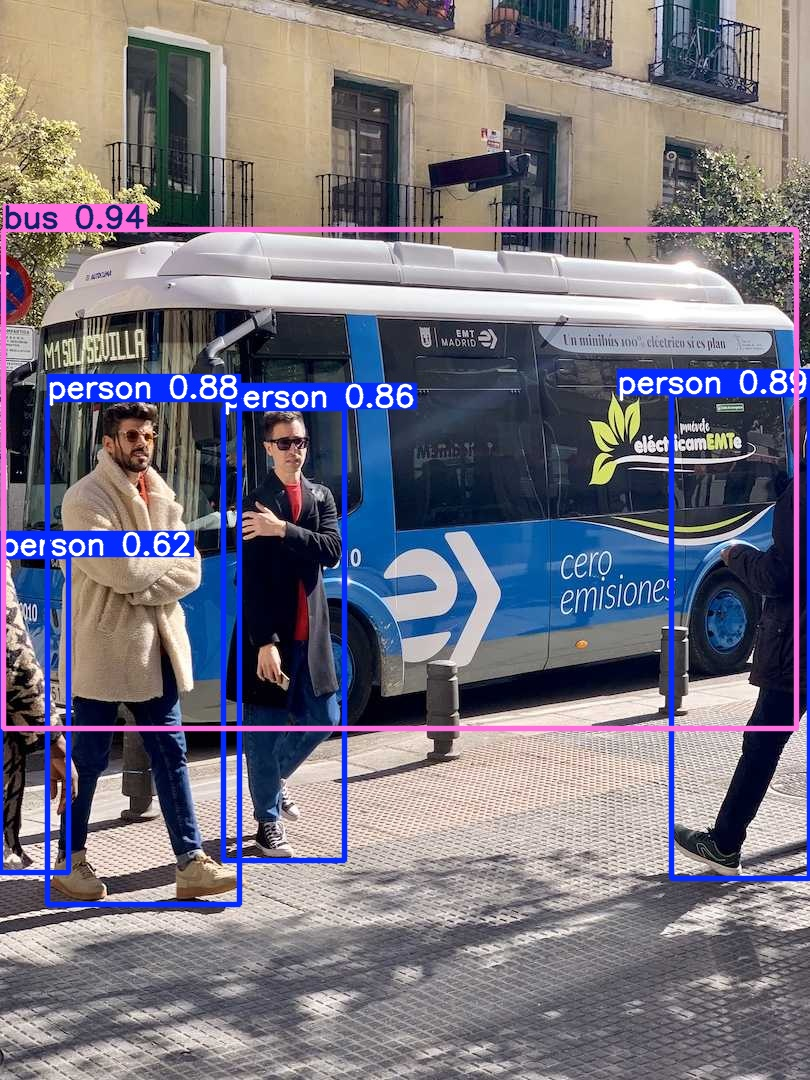

In [ ]:
from IPython.display import Image, display
display(Image(filename=predicted_image, width=800))

In [ ]:
#d- Apply model here
from ultralytics import YOLO
import os
from pathlib import Path

# Locate the dataset configuration file
yaml_path = os.path.join(
    os.path.dirname(__import__('ultralytics').__file__),
    'cfg', 'datasets', 'african-wildlife.yaml'
)

# Check that the YAML file exists
assert os.path.isfile(yaml_path), "African Wildlife YAML file not found!"

# Load the pretrained YOLO11 nano model
model = YOLO("yolo11n.pt")

# Train the model
results = model.train(
    data=yaml_path,
    epochs=10,
    batch=32,
    imgsz=640,
    plots=True,
    project=os.path.join(HOME, "runs", "detect"),
    name="african_wildlife"
)

# Save the directory where training results are stored
save_dir = Path(model.trainer.save_dir)


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/usr/local/lib/python3.13/dist-packages/ultralytics/cfg/datasets/african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=af

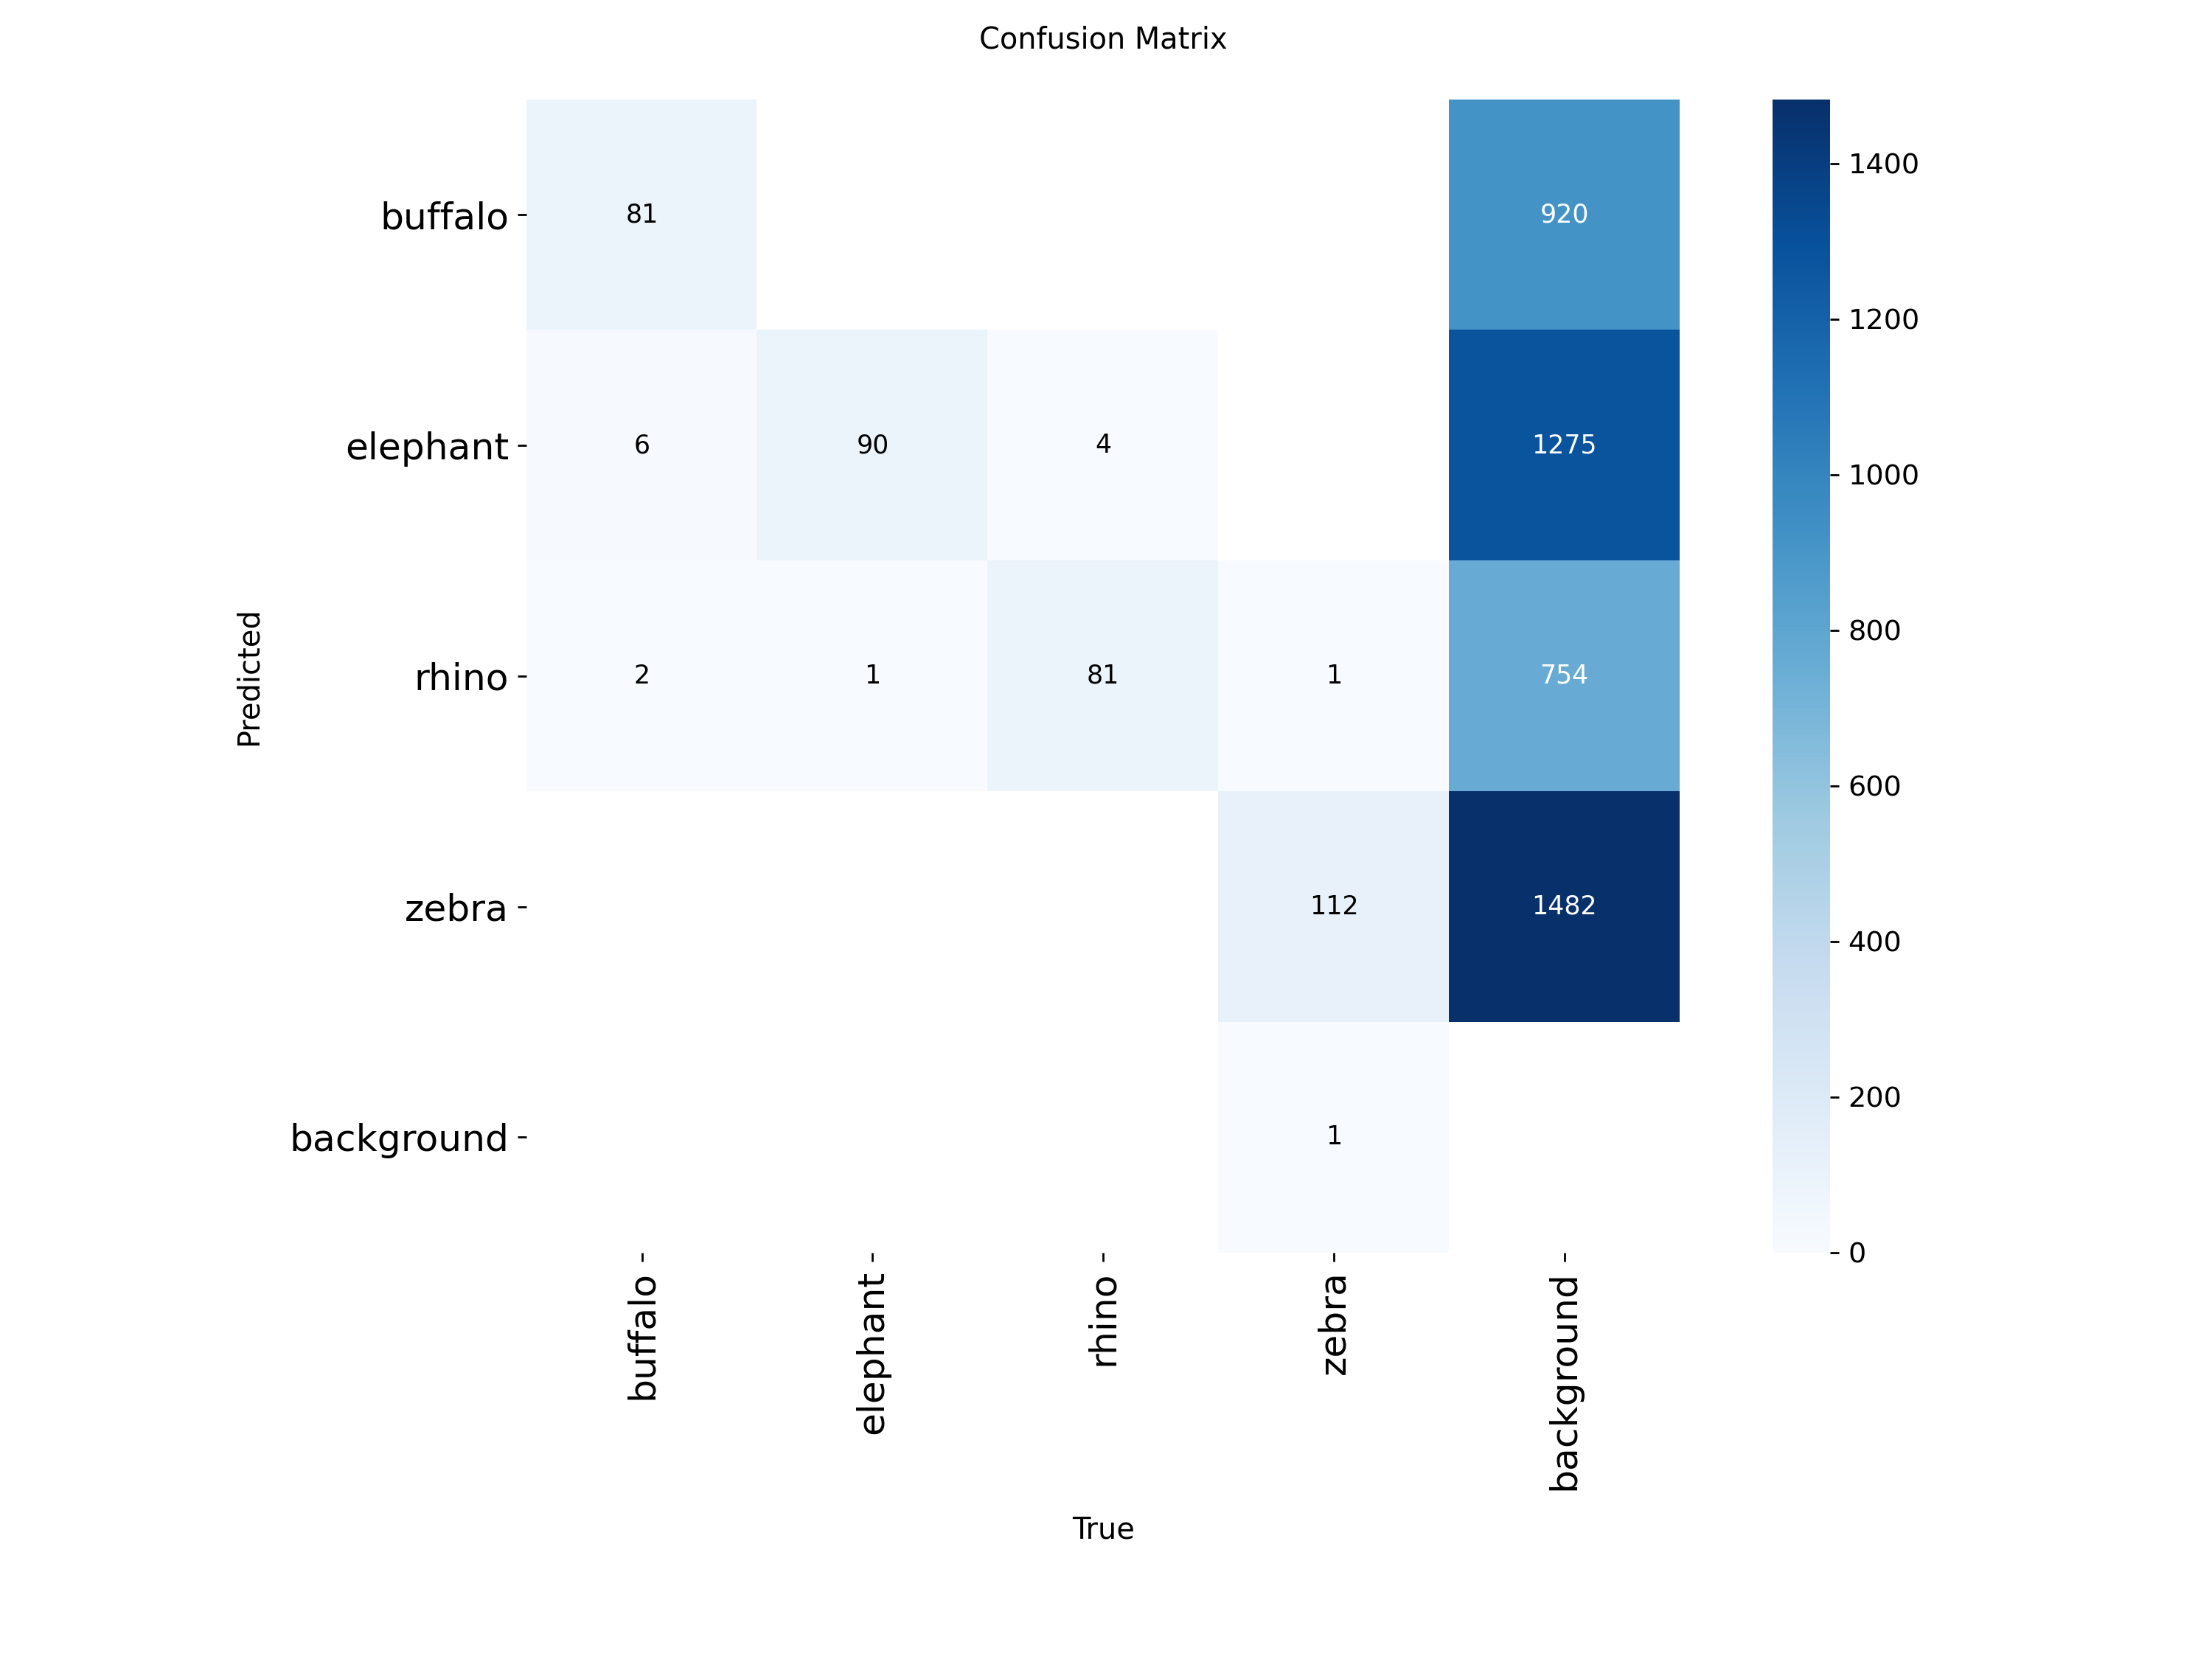

In [ ]:
#d- Fine-tune the model
# Show the learning curve and confusion matrix
from IPython.display import Image, display

confusion_matrix_path = save_dir / "confusion_matrix.png"

display(Image(filename=str(confusion_matrix_path)))

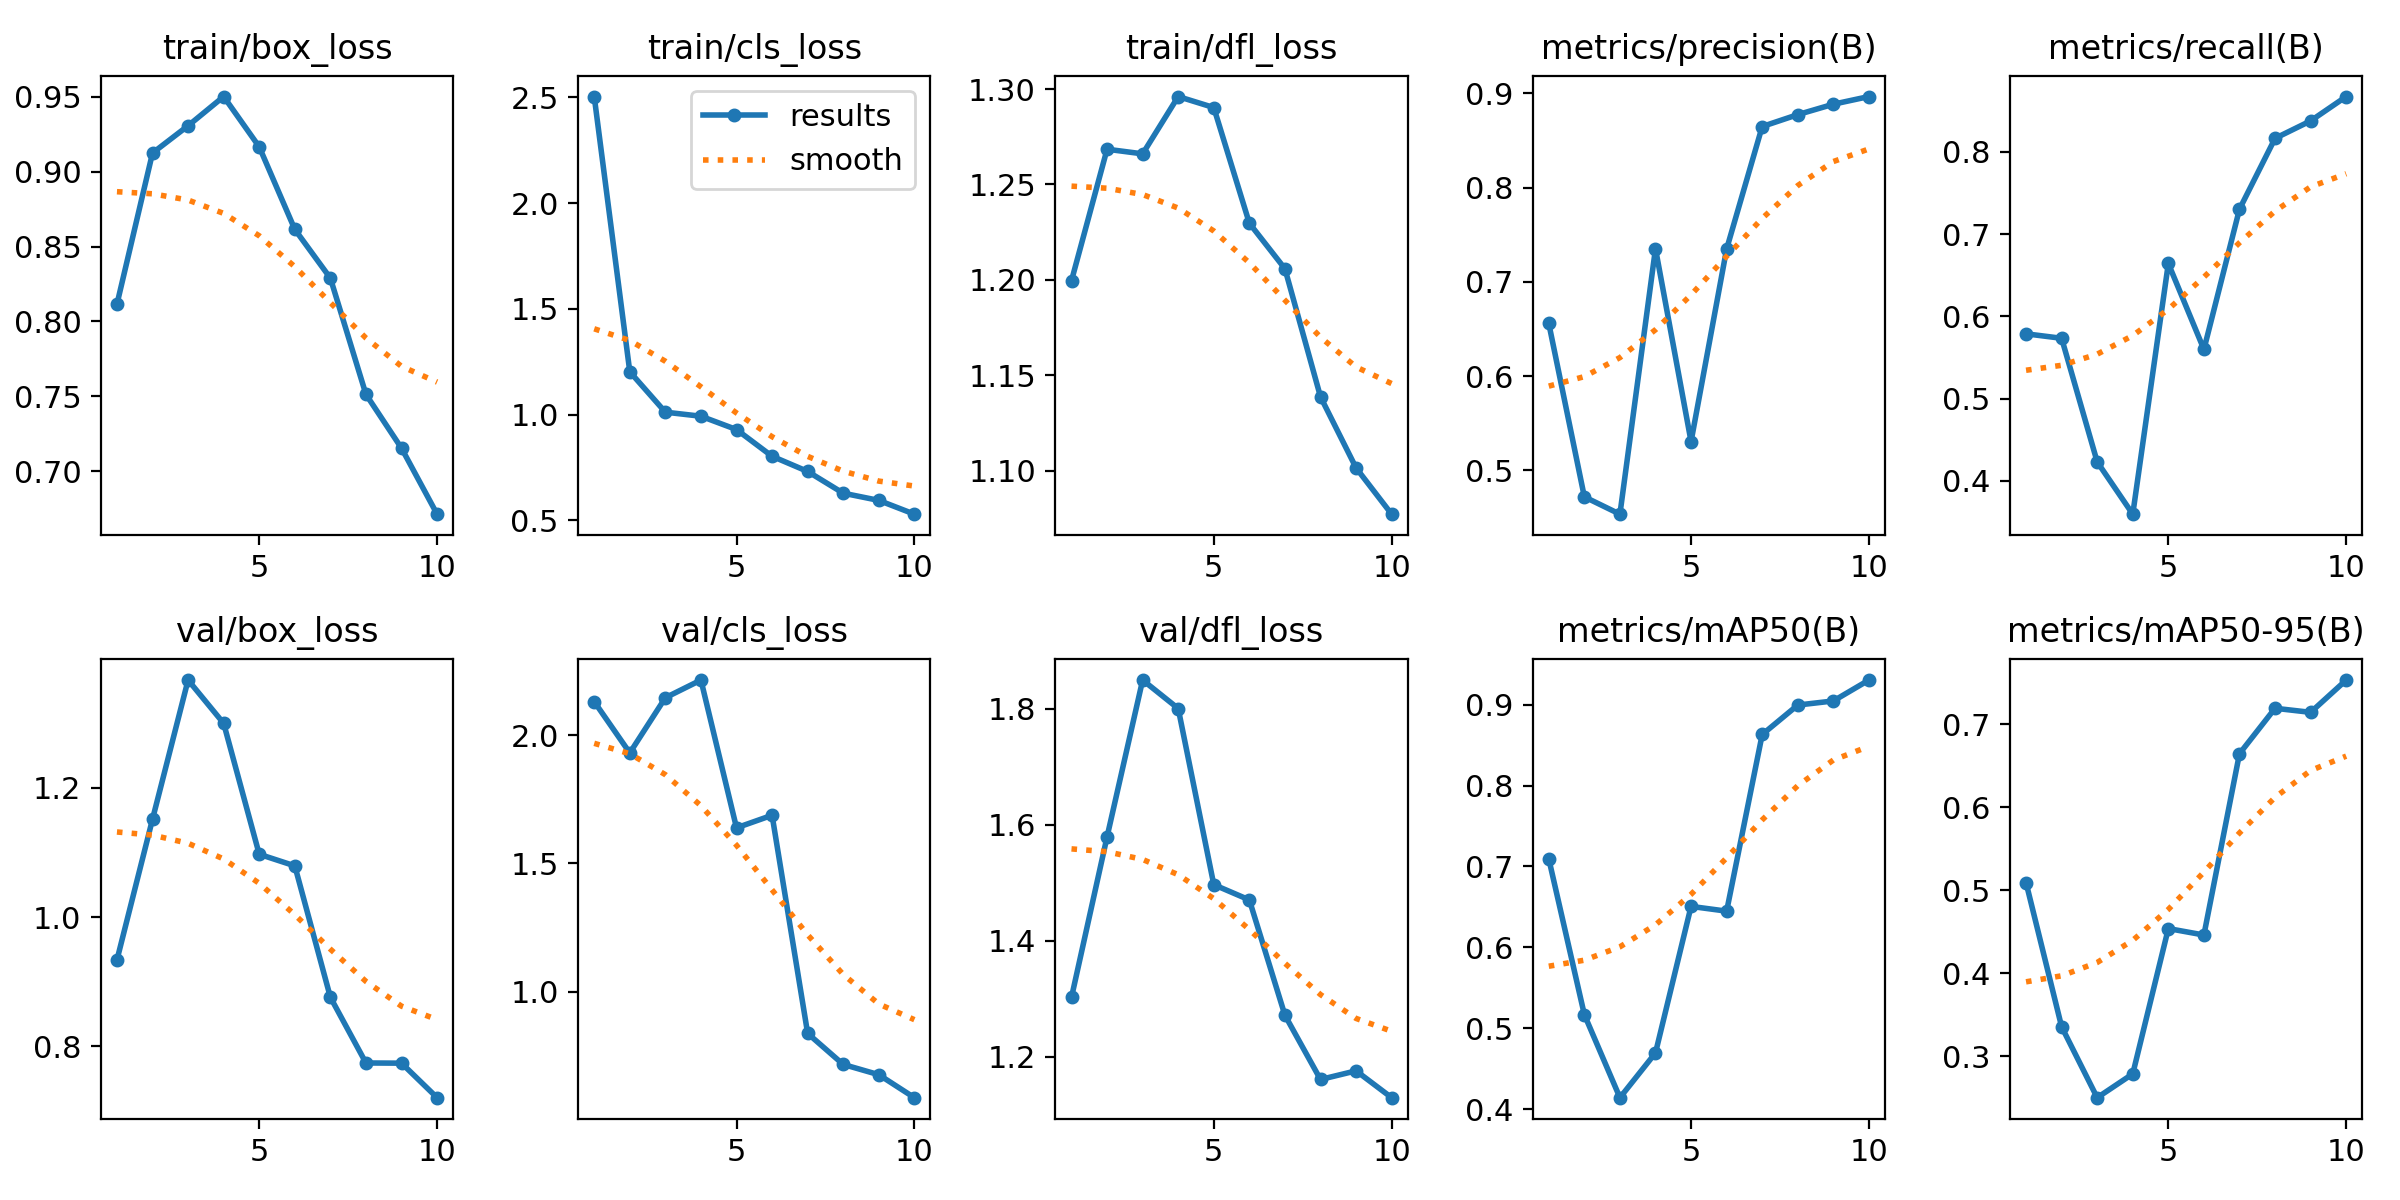

In [ ]:
learning_curves_path = save_dir / "results.png"

display(Image(filename=str(learning_curves_path)))

In [ ]:
#e) Explain what you see in the learning curves and confusion matrix.

**Learning Curves**

Training loss decreases as the nuber of epochs increases, this indicates the model is learning to identify and locate objects. Validation loss show the model generalizes correctly to images as it decreases with the number of epochs. There is no overfitting to the training data as there is no evidence of the training loss decreasing while the validation loss begins to increase. Recall, precision and mAP give more information about detection performance. Hence, its higher values are indicating better classification and detection skills.


**Confusion Matrix**

This confusion matrix shows accuracy when classifying the four categories of animals. It aids us understanding in which situations the model has more errors. In this case, we observe that when categorizing buffalos it will sometime classify it as a elephant and more rarely as rhino but never as a zebra.

In [ ]:
!apt-get update
!apt-get install texlive-xetex texlive-fonts-recommended texlive-latex-extra
!jupyter nbconvert /content/JuanTorres_Assignment3.ipynb --to pdf

Hit:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information...

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
